# Cross-dataset binary intrusion-detection experiments

## Research question

Does a binary malicious-traffic detector learn behavior that transfers between CICIDS2017 and CSE-CIC-IDS2018, and does exposure to both network environments improve robustness?

This notebook compares four fixed Logistic Regression training strategies:

1. **2017 only** — tests forward transfer from 2017 to 2018.
2. **2018 only** — tests reverse transfer from 2018 to 2017.
3. **Mixed, equal total budget** — uses half of the single-model row budget from each year, isolating the value of environmental diversity.
4. **Mixed, expanded budget** — uses the complete controlled training sample from each year, measuring the practical effect of diversity plus more data.

All strategies are evaluated separately on untouched chronological test partitions from both years. The primary metrics are binary macro F1, attack recall, attack F1, and benign false-alarm rate.

## Important design limitation

The repository contains the complete CICIDS2017 files but uses the cached **378,952-row stratified 2018 sample** created by the EDA workflow. The 2018 sample caps large classes and therefore does not preserve natural 2018 prevalence. Recall, false-alarm rate, and macro F1 remain useful, but precision and accuracy should not be interpreted as deployment prevalence estimates.

These experiments provide evidence about transfer within these two research datasets; they do not prove universal generalization to production networks.

In [1]:
import glob, os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')

ROOT = Path('../Data')
RESULTS_DIR = Path('results'); RESULTS_DIR.mkdir(parents=True, exist_ok=True)
D17 = ROOT / 'archive' / 'CICIDS2017_improved'
SAMPLE18 = ROOT / 'sample_2018_stratified.csv.gz'
RS = 42
TRAIN_BUDGET = 300_000

def signed_log(values):
    return np.sign(values) * np.log1p(np.abs(values))

def make_model():
    return make_pipeline(
        FunctionTransformer(signed_log),
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LogisticRegression(C=1.0, penalty='l2', solver='lbfgs', max_iter=1000,
                           class_weight='balanced', random_state=RS),
    )

/Users/ranga/.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /var/folders/8p/7ywd43m12fz07p58l3312vqh0000gn/T/matplotlib-d7xhehqy because there was an issue with the default path (/Users/ranga/.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/ranga/.cache/fontconfig
	/Users/ranga/.fontconfig


Matplotlib is building the font cache; this may take a moment.


## 1. Load and harmonize the two datasets

**Why we are doing this.** A cross-network model can use only measurements available in both datasets. Identifiers, timestamps, labels, and file metadata are excluded from the predictors.

**Business relevance.** Harmonization prevents a model from succeeding merely because one dataset contains a year-specific field that would not exist in another network.

In [2]:
files17 = sorted(glob.glob(str(D17 / '*.csv')))
if not files17:
    raise FileNotFoundError(f'No CICIDS2017 CSV files found under {D17}')
if not SAMPLE18.exists():
    raise FileNotFoundError('Run ../00_download_data.ipynb and the EDA sample-building step first.')

raw17 = pd.concat([pd.read_csv(path) for path in files17], ignore_index=True)
raw18 = pd.read_csv(SAMPLE18)

metadata = {
    'id', 'Flow ID', 'Src IP', 'Dst IP', 'Src Port', 'Timestamp',
    'Attempted Category', 'Label', 'file'
}
common = sorted((set(raw17.columns) & set(raw18.columns)) - metadata)
FEATURES = [column for column in common
            if pd.api.types.is_numeric_dtype(raw17[column])
            and pd.api.types.is_numeric_dtype(raw18[column])]

def prepare(raw, year):
    frame = raw[FEATURES].replace([np.inf, -np.inf], np.nan).astype('float32').copy()
    frame['raw_label'] = raw['Label'].astype(str).values
    frame['attempted'] = frame.raw_label.str.endswith(' - Attempted')
    frame['target'] = ((frame.raw_label != 'BENIGN') & ~frame.attempted).astype('int8')
    frame['ts'] = pd.to_datetime(raw['Timestamp'], errors='coerce').values
    frame['year'] = year
    before = len(frame)
    frame = frame.dropna(subset=['ts'])
    frame = frame.drop_duplicates(subset=FEATURES + ['target']).reset_index(drop=True)
    print(f'{year}: {before:,} input rows | {len(frame):,} retained | {before-len(frame):,} missing-time/duplicate rows removed')
    return frame

data17 = prepare(raw17, '2017')
data18 = prepare(raw18, '2018 sample')
del raw17, raw18

inventory = pd.DataFrame({
    'rows': [len(data17), len(data18)],
    'effective attacks': [data17.target.sum(), data18.target.sum()],
    'benign or attempted': [(data17.target == 0).sum(), (data18.target == 0).sum()],
}, index=['2017', '2018 sample'])
print(f'Common numeric features: {len(FEATURES)}')
display(inventory)

2017: 2,099,976 input rows | 1,836,615 retained | 263,361 missing-time/duplicate rows removed


2018 sample: 378,952 input rows | 335,828 retained | 43,124 missing-time/duplicate rows removed
Common numeric features: 83


,rows,effective attacks,benign or attempted
2017,1836615,402029,1434586
2018 sample,335828,145379,190449


**Takeaway.** Both years now use the same predictor columns and the same binary label policy. Labels ending in `- Attempted` are scored as benign, matching the Phase 1 baseline.

## 2. Build independent chronological partitions

**Why we are doing this.** Within each original label, the earliest 80% is reserved for training and the latest 20% for testing. The split is performed separately by year before any data are mixed.

**Business relevance.** This prevents the mixed model from seeing its test records during training and makes each evaluation resemble training on earlier activity and detecting later activity.

The split is chronological within label because attacks occur on different scheduled days. This retains each available family on both sides when enough observations exist, but it cannot eliminate every laboratory-event dependency.

In [3]:
def chronological_split(frame):
    rank = frame.groupby('raw_label')['ts'].rank(method='first', pct=True)
    return frame.index[rank <= 0.80].to_numpy(), frame.index[rank > 0.80].to_numpy()

train17_idx, test17_idx = chronological_split(data17)
train18_idx, test18_idx = chronological_split(data18)

split_sizes = pd.DataFrame({
    'train rows': [len(train17_idx), len(train18_idx)],
    'test rows': [len(test17_idx), len(test18_idx)],
    'train attack share': [data17.target.iloc[train17_idx].mean(), data18.target.iloc[train18_idx].mean()],
    'test attack share': [data17.target.iloc[test17_idx].mean(), data18.target.iloc[test18_idx].mean()],
}, index=['2017', '2018 sample'])
display(split_sizes.style.format({'train attack share': '{:.2%}', 'test attack share': '{:.2%}'}))

,train rows,test rows,train attack share,test attack share
2017,1469282,367333,21.89%,21.89%
2018 sample,268654,67174,43.29%,43.29%


## 3. Construct controlled training strategies

**Why we are doing this.** Unequal training sizes can make a domain look better simply because it contributes more rows. The 2017-only and 2018-only models therefore receive the same row budget. The equal-budget mixed model receives the same total budget, divided equally by year. The expanded mixed model receives one full budget from each year.

**Business relevance.** This separates the benefit of seeing multiple network environments from the benefit of merely processing more data.

In [4]:
def stratified_sample(frame, indices, size, seed):
    indices = np.asarray(indices)
    if len(indices) <= size:
        return indices.copy()
    rng = np.random.default_rng(seed)
    selected = []
    targets = frame.target.iloc[indices].to_numpy()
    for target in [0, 1]:
        group = indices[targets == target]
        allocation = int(round(size * len(group) / len(indices)))
        allocation = min(allocation, len(group))
        selected.append(rng.choice(group, allocation, replace=False))
    result = np.concatenate(selected)
    if len(result) > size:
        result = rng.choice(result, size, replace=False)
    elif len(result) < size:
        remaining = np.setdiff1d(indices, result, assume_unique=False)
        result = np.r_[result, rng.choice(remaining, size-len(result), replace=False)]
    rng.shuffle(result)
    return result

budget = min(TRAIN_BUDGET, len(train17_idx), len(train18_idx))
full17 = stratified_sample(data17, train17_idx, budget, RS)
full18 = stratified_sample(data18, train18_idx, budget, RS + 1)
half17 = stratified_sample(data17, train17_idx, budget // 2, RS + 2)
half18 = stratified_sample(data18, train18_idx, budget - budget // 2, RS + 3)

train_sets = {
    '2017 only': (data17.iloc[full17][FEATURES], data17.target.iloc[full17].to_numpy()),
    '2018 only': (data18.iloc[full18][FEATURES], data18.target.iloc[full18].to_numpy()),
    'Mixed equal budget': (
        pd.concat([data17.iloc[half17][FEATURES], data18.iloc[half18][FEATURES]], ignore_index=True),
        np.r_[data17.target.iloc[half17].to_numpy(), data18.target.iloc[half18].to_numpy()]),
    'Mixed expanded budget': (
        pd.concat([data17.iloc[full17][FEATURES], data18.iloc[full18][FEATURES]], ignore_index=True),
        np.r_[data17.target.iloc[full17].to_numpy(), data18.target.iloc[full18].to_numpy()]),
}

training_design = pd.DataFrame([
    {'strategy': name, 'rows': len(y), 'attack share': y.mean()}
    for name, (_, y) in train_sets.items()
])
display(training_design.style.format({'attack share': '{:.2%}'}))

,strategy,rows,attack share
0,2017 only,268654,21.89%
1,2018 only,268654,43.29%
2,Mixed equal budget,268654,32.59%
3,Mixed expanded budget,537308,32.59%


## 4. Fit each strategy and evaluate both years

All models use the same signed-log transformation, median imputation, standardization, balanced class weights, and L2 Logistic Regression settings. No configuration is selected using either test partition.

In [5]:
test_sets = {
    '2017 test': (data17.iloc[test17_idx][FEATURES], data17.target.iloc[test17_idx].to_numpy()),
    '2018 test': (data18.iloc[test18_idx][FEATURES], data18.target.iloc[test18_idx].to_numpy()),
}

models, predictions, result_rows, confusion_rows = {}, {}, [], []
for strategy, (X_train, y_train) in train_sets.items():
    model = make_model()
    started = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - started
    models[strategy] = model
    print(f'{strategy:<24} fitted on {len(y_train):,} rows in {fit_seconds:.1f}s')
    for test_name, (X_test, y_test) in test_sets.items():
        pred = model.predict(X_test)
        score = model.predict_proba(X_test)[:, 1]
        predictions[(strategy, test_name)] = pred
        precision, recall, f1, support = precision_recall_fscore_support(
            y_test, pred, labels=[0, 1], zero_division=0
        )
        matrix = confusion_matrix(y_test, pred, labels=[0, 1])
        tn, fp, fn, tp = matrix.ravel()
        result_rows.append({
            'training strategy': strategy, 'test dataset': test_name,
            'training rows': len(y_train), 'test rows': len(y_test),
            'macro_f1': f1.mean(), 'attack_precision': precision[1],
            'attack_recall': recall[1], 'attack_f1': f1[1],
            'false_alarm_rate': fp / (fp + tn),
            'benign_recall': recall[0], 'roc_auc': roc_auc_score(y_test, score),
            'accuracy': accuracy_score(y_test, pred), 'fit_seconds': fit_seconds,
        })
        confusion_rows.append({
            'training strategy': strategy, 'test dataset': test_name,
            'true_benign_pred_benign': tn, 'true_benign_pred_attack': fp,
            'true_attack_pred_benign': fn, 'true_attack_pred_attack': tp,
        })

results = pd.DataFrame(result_rows)
confusions = pd.DataFrame(confusion_rows)
results.to_csv(RESULTS_DIR / '06_cross_dataset_summary.csv', index=False)
confusions.to_csv(RESULTS_DIR / '06_cross_dataset_confusion_counts.csv', index=False)
display(results.sort_values(['test dataset', 'macro_f1'], ascending=[True, False]).round(4))

2017 only                fitted on 268,654 rows in 5.5s


2018 only                fitted on 268,654 rows in 11.2s


Mixed equal budget       fitted on 268,654 rows in 8.8s


Mixed expanded budget    fitted on 537,308 rows in 18.0s


,training strategy,test dataset,training rows,test rows,macro_f1,attack_precision,attack_recall,attack_f1,false_alarm_rate,benign_recall,roc_auc,accuracy,fit_seconds
0,2017 only,2017 test,268654,367333,0.9900,0.9775,0.9912,0.9843,0.0064,0.9936,0.9988,0.9931,5.4681
6,Mixed expanded budget,2017 test,537308,367333,0.9629,0.9023,0.9870,0.9428,0.0299,0.9701,0.9923,0.9738,17.9612
4,Mixed equal budget,2017 test,268654,367333,0.9617,0.8994,0.9865,0.9410,0.0309,0.9691,0.9922,0.9729,8.7799
2,2018 only,2017 test,268654,367333,0.7945,0.6758,0.6832,0.6795,0.0919,0.9081,0.8466,0.8589,11.1847
3,2018 only,2018 test,268654,67174,0.9851,0.9822,0.9841,0.9831,0.0137,0.9863,0.9924,0.9854,11.1847
7,Mixed expanded budget,2018 test,537308,67174,0.9675,0.9498,0.9776,0.9635,0.0394,0.9606,0.9891,0.9679,17.9612
5,Mixed equal budget,2018 test,268654,67174,0.9667,0.9480,0.9778,0.9626,0.0410,0.9590,0.9887,0.9671,8.7799
1,2017 only,2018 test,268654,67174,0.6936,0.8726,0.4424,0.5871,0.0493,0.9507,0.8403,0.7307,5.4681


## 5. Compare generalization and false alarms

**Why we are doing this.** A useful intrusion detector must find attacks without overwhelming analysts with benign alerts. Macro F1 summarizes both classes, while attack recall and false-alarm rate expose the operational tradeoff.

**Business relevance.** The best strategy is not necessarily the one with the highest attack recall; an unmanageable false-alarm rate can make the detector unusable.

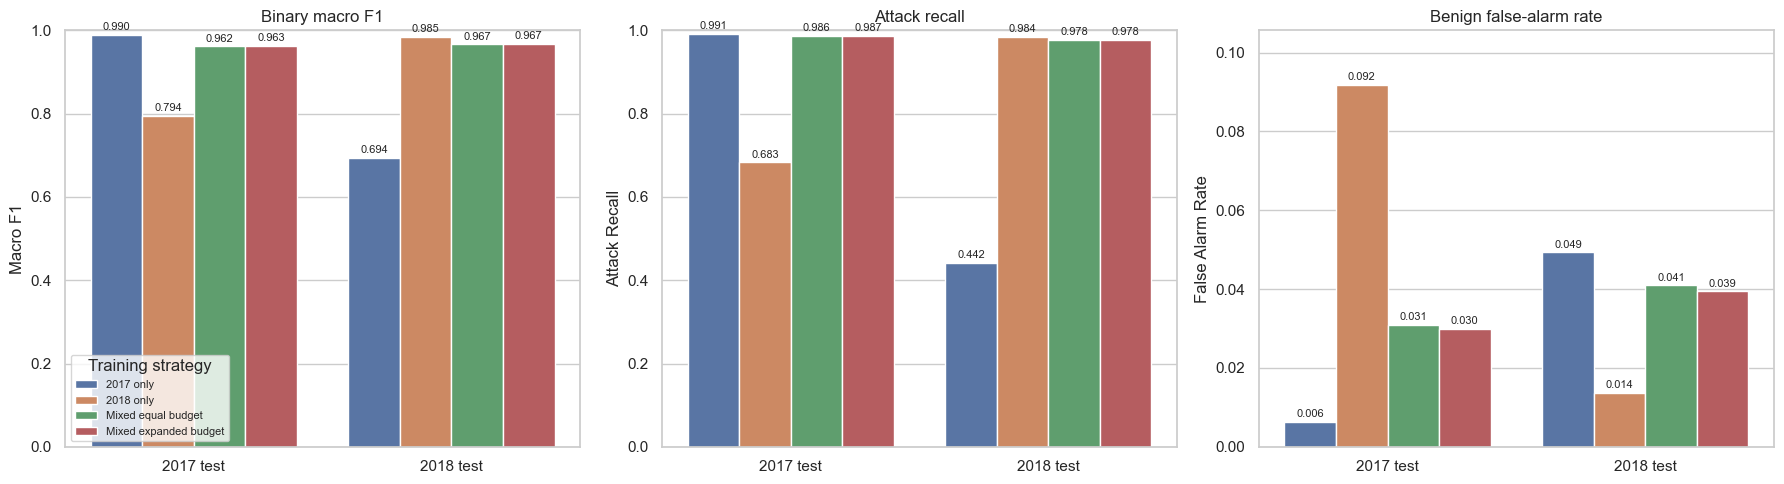

macro_f1           attack_recall           false_alarm_rate          
test dataset          2017 test 2018 test     2017 test 2018 test        2017 test 2018 test
training strategy                                                                           
2017 only                0.9900    0.6936        0.9912    0.4424           0.0064    0.0493
2018 only                0.7945    0.9851        0.6832    0.9841           0.0919    0.0137
Mixed equal budget       0.9617    0.9667        0.9865    0.9778           0.0309    0.0410
Mixed expanded budget    0.9629    0.9675        0.9870    0.9776           0.0299    0.0394

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_metrics = [
    ('macro_f1', 'Binary macro F1', (0, 1)),
    ('attack_recall', 'Attack recall', (0, 1)),
    ('false_alarm_rate', 'Benign false-alarm rate', (0, max(0.05, results.false_alarm_rate.max() * 1.15))),
]
for ax, (metric, title, limits) in zip(axes, plot_metrics):
    sns.barplot(data=results, x='test dataset', y=metric, hue='training strategy', ax=ax)
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel(metric.replace('_', ' ').title())
    ax.set_ylim(*limits); ax.tick_params(axis='x', rotation=0)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)
axes[0].legend(title='Training strategy', fontsize=8)
axes[1].get_legend().remove(); axes[2].get_legend().remove()
plt.tight_layout(); plt.show()

pivot = results.pivot(index='training strategy', columns='test dataset',
                      values=['macro_f1', 'attack_recall', 'false_alarm_rate'])
display(pivot.round(4))

## 6. Attack-family alarm rates

Binary summary metrics can hide attack families that do not transfer. The table below reports the fraction of each family flagged as malicious. For benign traffic this is the false-alarm rate; attempted labels are shown separately even though they are scored as benign.

In [7]:
MAP18 = {
    'BENIGN': 'BENIGN', 'SSH-BruteForce': 'SSH-Patator', 'DoS Hulk': 'DoS Hulk',
    'DoS GoldenEye': 'DoS GoldenEye', 'DoS Slowloris': 'DoS Slowloris',
    'DDoS-LOIC-HTTP': 'DDoS', 'Botnet Ares': 'Botnet',
    'Infiltration - NMAP Portscan': 'Infiltration - Portscan',
    'Web Attack - Brute Force': 'Web Attack - Brute Force',
    'Web Attack - XSS': 'Web Attack - XSS', 'Web Attack - SQL': 'Web Attack - SQL Injection',
    'Infiltration - Communication Victim Attacker': 'Infiltration',
}

def evaluation_groups(frame, year):
    label = frame.raw_label.copy()
    if year == '2018':
        label = label.map(MAP18).fillna(label)
    return np.where(frame.attempted, 'Attempted (scored as benign)', label)

family_rows = []
for test_name, frame, indices in [
    ('2017 test', data17, test17_idx), ('2018 test', data18, test18_idx)
]:
    groups = evaluation_groups(frame.iloc[indices], test_name[:4])
    for strategy in train_sets:
        pred = predictions[(strategy, test_name)]
        rates = pd.Series(pred).groupby(groups).agg(['mean', 'size'])
        for family, row in rates.iterrows():
            family_rows.append({
                'training strategy': strategy, 'test dataset': test_name,
                'evaluation group': family, 'alarm_rate': row['mean'],
                'support': int(row['size']),
            })

family_results = pd.DataFrame(family_rows)
family_results.to_csv(RESULTS_DIR / '06_cross_dataset_family_detection.csv', index=False)
common_display = family_results[family_results.support >= 20].pivot_table(
    index=['test dataset', 'evaluation group'], columns='training strategy', values='alarm_rate'
)
display(common_display.round(4))

training strategy                          2017 only  2018 only  Mixed equal budget  Mixed expanded budget
test dataset evaluation group                                                                             
2017 test    Attempted (scored as benign)     0.0806     0.2396              0.1530                 0.1530
             BENIGN                           0.0059     0.0909              0.0301                 0.0292
             Botnet                           0.0000     0.6216              0.0000                 0.0000
             DDoS                             1.0000     0.7999              0.9964                 0.9965
             DoS GoldenEye                    0.9392     0.9359              0.9815                 0.9802
             DoS Hulk                         0.9991     0.3350              0.9878                 0.9891
             DoS Slowhttptest                 0.6379     1.0000              0.9713                 0.8822
             DoS Slowloris                    0.9689     1.0000              0.9767                 0.9767
             FTP-Patator                      1.0000     0.9975              0.8528                 0.8956
             Infiltration - Portscan          0.9783     0.9670              0.9722                 0.9731
             Portscan                         0.9948     0.9905              0.9959                 0.9953
             SSH-Patator                      0.9865     0.9848              0.9713                 0.9696
2018 test    Attempted (scored as benign)     0.6091     0.1030              0.4031                 0.3963
             BENIGN                           0.0269     0.0101              0.0265                 0.0251
             Botnet                           0.0018     1.0000              0.9985                 0.9990
             DDoS                             1.0000     1.0000              1.0000                 1.0000
             DDoS-HOIC                        0.0000     0.9905              0.9908                 0.9908
             DDoS-LOIC-UDP                    0.0000     0.9822              0.9783                 0.9783
             DoS GoldenEye                    0.5868     0.9892              0.9752                 0.9758
             DoS Hulk                         0.0148     1.0000              0.9825                 0.9838
             DoS Slowloris                    0.9706     1.0000              0.9894                 0.9882
             Infiltration                     0.0000     0.2439              0.0244                 0.0244
             Infiltration - Portscan          0.7390     0.8924              0.8916                 0.8876
             SSH-Patator                      0.6912     1.0000              1.0000                 1.0000
             Web Attack - Brute Force         0.0000     0.0000              0.0000                 0.0000
             Web Attack - XSS                 0.0000     1.0000              0.0000                 0.0000

## 7. Programmatic findings

The statements below are generated from the measured results, so they update automatically if the data or experiment design changes.

In [8]:
def value(strategy, test, metric):
    return results.loc[
        results['training strategy'].eq(strategy) & results['test dataset'].eq(test), metric
    ].iloc[0]

forward = value('2017 only', '2018 test', 'macro_f1')
reverse = value('2018 only', '2017 test', 'macro_f1')
own17 = value('2017 only', '2017 test', 'macro_f1')
own18 = value('2018 only', '2018 test', 'macro_f1')
mixed17 = value('Mixed equal budget', '2017 test', 'macro_f1')
mixed18 = value('Mixed equal budget', '2018 test', 'macro_f1')
expanded17 = value('Mixed expanded budget', '2017 test', 'macro_f1')
expanded18 = value('Mixed expanded budget', '2018 test', 'macro_f1')

average_scores = results.groupby('training strategy').macro_f1.mean().sort_values(ascending=False)
best_average = average_scores.index[0]

findings = pd.DataFrame([
    ('Forward transfer', 'Train 2017 → test 2018',
     f'Macro F1 {forward:.4f}; within-2017 score {own17:.4f}; transfer change {forward-own17:+.4f}.'),
    ('Reverse transfer', 'Train 2018 → test 2017',
     f'Macro F1 {reverse:.4f}; within-2018 score {own18:.4f}; transfer change {reverse-own18:+.4f}.'),
    ('Directionality', 'Cross-network macro F1',
     f'Forward {forward:.4f} versus reverse {reverse:.4f}; difference {forward-reverse:+.4f}.'),
    ('Diversity at fixed budget', 'Mixed equal-budget versus matching single-year model',
     f'2017 test change {mixed17-own17:+.4f}; 2018 test change {mixed18-own18:+.4f}.'),
    ('Diversity plus more data', 'Mixed expanded versus matching single-year model',
     f'2017 test change {expanded17-own17:+.4f}; 2018 test change {expanded18-own18:+.4f}.'),
    ('Best average robustness', best_average,
     f'Average macro F1 across both test datasets: {average_scores.iloc[0]:.4f}.'),
], columns=['Question', 'Comparison', 'Measured result'])
display(findings.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

print('Interpretation guardrail: these findings establish evidence for these benchmark environments, not universal production-network performance.')

Question,Comparison,Measured result
Forward transfer,Train 2017 → test 2018,Macro F1 0.6936; within-2017 score 0.9900; transfer change -0.2963.
Reverse transfer,Train 2018 → test 2017,Macro F1 0.7945; within-2018 score 0.9851; transfer change -0.1906.
Directionality,Cross-network macro F1,Forward 0.6936 versus reverse 0.7945; difference -0.1009.
Diversity at fixed budget,Mixed equal-budget versus matching single-year model,2017 test change -0.0283; 2018 test change -0.0184.
Diversity plus more data,Mixed expanded versus matching single-year model,2017 test change -0.0271; 2018 test change -0.0176.
Best average robustness,Mixed expanded budget,Average macro F1 across both test datasets: 0.9652.


Interpretation guardrail: these findings establish evidence for these benchmark environments, not universal production-network performance.


## Final takeaway

Use the programmatic findings above to determine whether transfer is symmetric and whether mixed-network training improves both years. A mixed strategy supports the diversity hypothesis only if it improves—or at least stabilizes—performance across both independent test datasets without producing an unacceptable false-alarm increase.

The mixed-year result measures robustness across two environments already represented in training. It must not be described as proof that the model will generalize to an unseen third network. That stronger claim would require another independently collected dataset held out from every development decision.

Even a negative result is valuable: it would show that pooling datasets is insufficient and that explicit domain adaptation, feature redesign, or network-specific recalibration may be necessary.